# Regression Baselines

## Imports

In [9]:
import os
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt

import ipywidgets as widgets
from IPython.display import display

## Load Data

In [2]:
base_dir = os.path.join(os.getcwd(), '..')
processed_data_dir = os.path.join(base_dir, 'processed_data')

open_meteo_filepath = os.path.join(processed_data_dir, 'open_meteo_processed_data.csv')
open_meteo_df = pd.read_csv(open_meteo_filepath, parse_dates=['datetime'])

ausgrid_filepath = os.path.join(processed_data_dir, 'ausgrid_processed_data.csv')
ausgrid_df = pd.read_csv(ausgrid_filepath, parse_dates=['datetime'])

## Make Datasets

In [3]:
# Merge weather data onto each smart-meter reading, then split chronologically
data = ausgrid_df.merge(open_meteo_df, on="datetime", how="left").sort_values("datetime")

# Split into training and testing data
cutoff = data["datetime"].drop_duplicates().sort_values().iloc[
    int(0.8 * data["datetime"].nunique())]

train_df = data[data["datetime"] < cutoff]
test_df = data[data["datetime"] >= cutoff]

## Average Baseline

In [6]:
# Half-hour slot within the day (0–47)
train_month = train_df["datetime"].dt.month
train_slot = train_df["datetime"].dt.hour * 2 + train_df["datetime"].dt.minute // 30

test_month = test_df["datetime"].dt.month
test_slot = test_df["datetime"].dt.hour * 2 + test_df["datetime"].dt.minute // 30

# Average historical PV generation by customer, month, and half-hour slot
monthly_profile = (
    pd.DataFrame({
        "Customer": train_df["Customer"].to_numpy(),
        "month": train_month.to_numpy(),
        "slot": train_slot.to_numpy(),
        "Pgen": train_df["Pgen"].to_numpy(),
    })
    .groupby(["Customer", "month", "slot"])["Pgen"]
    .mean()
)

# Fallback profile for month/slot combinations not present in training data
slot_profile = (
    pd.DataFrame({
        "Customer": train_df["Customer"].to_numpy(),
        "slot": train_slot.to_numpy(),
        "Pgen": train_df["Pgen"].to_numpy(),
    })
    .groupby(["Customer", "slot"])["Pgen"]
    .mean()
)

test_keys = pd.MultiIndex.from_arrays(
    [test_df["Customer"].to_numpy(), test_month.to_numpy(), test_slot.to_numpy()]
)
fallback_keys = pd.MultiIndex.from_arrays(
    [test_df["Customer"].to_numpy(), test_slot.to_numpy()]
)

predictions = monthly_profile.reindex(test_keys)
fallback_predictions = slot_profile.reindex(fallback_keys).to_numpy()
predictions = predictions.to_numpy()
predictions = np.where(pd.isna(predictions), fallback_predictions, predictions)

test_df["Pgen_pred"] = predictions

### Plot mean predictor results

In [8]:
test_plot_df = test_df.set_index("datetime").sort_index()
days = sorted(test_df["datetime"].dt.date.unique())
customers = sorted(test_df["Customer"].unique())

day_dropdown = widgets.Dropdown(options=days, description="Day:")
customer_dropdown = widgets.Dropdown(options=customers, description="Customer:")

def plot_customer_day(day, customer):
    start = pd.Timestamp(day)
    end = start + pd.Timedelta(days=1)
    day_data = test_plot_df.loc[start:end]
    customer_data = day_data[day_data["Customer"] == customer]

    ax = customer_data[["Pgen", "Pgen_pred"]].plot(figsize=(14, 5), linewidth=1)
    ax.set(
        title=f"Actual vs. Predicted PV Generation — Customer {customer}, {day}",
        xlabel="Time",
        ylabel="PV generation",
    )
    ax.legend(["Actual", "Predicted"])
    plt.tight_layout()
    plt.show()

controls = widgets.HBox([day_dropdown, customer_dropdown])
output = widgets.interactive_output(
    plot_customer_day,
    {"day": day_dropdown, "customer": customer_dropdown},
)
display(controls, output)

Output()

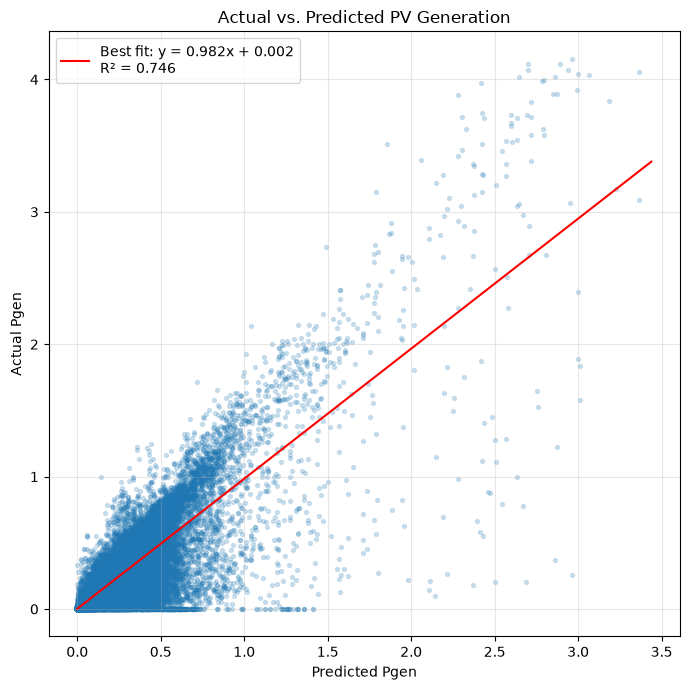

In [10]:
# Compare actual and predicted generation across the test set
scatter_df = test_df[["Pgen", "Pgen_pred"]].dropna()
x = scatter_df["Pgen_pred"].to_numpy()
y = scatter_df["Pgen"].to_numpy()

# Best-fit line and R², calculated using all valid observations
slope, intercept = np.polyfit(x, y, 1)
y_fit = slope * x + intercept
r2 = 1 - np.sum((y - y_fit) ** 2) / np.sum((y - y.mean()) ** 2)

# Plot a sample of points for performance
plot_sample = scatter_df.sample(n=min(100_000, len(scatter_df)), random_state=42)

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(plot_sample["Pgen_pred"], plot_sample["Pgen"], alpha=0.2, s=8)

line_x = np.linspace(x.min(), x.max(), 100)
ax.plot(line_x, slope * line_x + intercept, color="red",
    label=f"Best fit: y = {slope:.3f}x + {intercept:.3f}\nR² = {r2:.3f}")

ax.set(
    title="Actual vs. Predicted PV Generation",
    xlabel="Predicted Pgen",
    ylabel="Actual Pgen",
)
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Previous Day Predictor Baseline

In [11]:
# Match each test observation to that customer's reading exactly one day earlier.
# Restrict the lookup to timestamps needed by the test set to limit memory use.
previous_times = pd.DatetimeIndex(test_df["datetime"].unique()) - pd.Timedelta(days=1)

previous_day_lookup = (
    data.loc[data["datetime"].isin(previous_times), ["Customer", "datetime", "Pgen"]]
    .rename(columns={
        "datetime": "previous_datetime",
        "Pgen": "Pgen_prev_day",
    })
)

# Preserve the original test_df row order while merging.
test_rows = test_df[["Customer", "datetime"]].copy()
test_rows["_row_id"] = np.arange(len(test_rows))
test_rows["previous_datetime"] = test_rows["datetime"] - pd.Timedelta(days=1)

previous_day_predictions = test_rows.merge(
    previous_day_lookup,
    on=["Customer", "previous_datetime"],
    how="left",
    validate="many_to_one",
).sort_values("_row_id")

test_df["Pgen_prev_day"] = previous_day_predictions["Pgen_prev_day"].to_numpy()

# Evaluate where both actual and predicted values are available.
valid = test_df[["Pgen", "Pgen_prev_day"]].dropna()
mae = np.mean(np.abs(valid["Pgen"] - valid["Pgen_prev_day"]))
rmse = np.sqrt(np.mean((valid["Pgen"] - valid["Pgen_prev_day"]) ** 2))

print(f"Valid observations: {len(valid):,}")
print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")

# Interactive plot using the existing day and customer dropdowns.
test_plot_df = test_df.set_index("datetime").sort_index()

def plot_previous_day(day, customer):
    start = pd.Timestamp(day)
    end = start + pd.Timedelta(days=1)

    day_data = test_plot_df.loc[
        (test_plot_df.index >= start) & (test_plot_df.index < end)
    ]
    customer_data = day_data.loc[day_data["Customer"] == customer]

    ax = customer_data[["Pgen", "Pgen_prev_day"]].plot(
        figsize=(14, 5), linewidth=1
    )
    ax.set(
        title=f"Actual vs. Previous-Day PV Generation — Customer {customer}, {day}",
        xlabel="Time",
        ylabel="PV generation",
    )
    ax.legend(["Actual", "Previous day"])
    plt.tight_layout()
    plt.show()

output = widgets.interactive_output(
    plot_previous_day,
    {"day": day_dropdown, "customer": customer_dropdown},
)
display(controls, output)

Valid observations: 3,154,718
MAE:  0.0530
RMSE: 0.1406


Output()

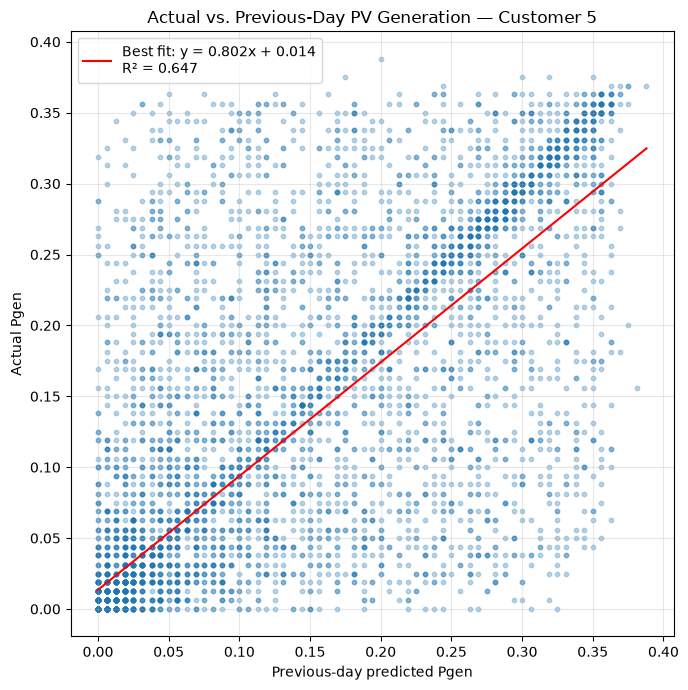

In [12]:
customer_id = customer_dropdown.value
scatter_customer_df = (
    test_df.loc[test_df["Customer"] == customer_id, ["Pgen", "Pgen_prev_day"]]
    .dropna()
)

x_customer = scatter_customer_df["Pgen_prev_day"].to_numpy()
y_customer = scatter_customer_df["Pgen"].to_numpy()

if len(scatter_customer_df) < 2 or np.ptp(x_customer) == 0 or np.ptp(y_customer) == 0:
    print(f"Not enough variation to fit a line for customer {customer_id}.")
else:
    slope_customer, intercept_customer = np.polyfit(x_customer, y_customer, 1)
    y_fit_customer = slope_customer * x_customer + intercept_customer
    r2_customer = 1 - np.sum((y_customer - y_fit_customer) ** 2) / np.sum(
        (y_customer - y_customer.mean()) ** 2
    )

    fig, ax = plt.subplots(figsize=(7, 7))
    ax.scatter(x_customer, y_customer, alpha=0.3, s=10)

    line_x_customer = np.linspace(x_customer.min(), x_customer.max(), 100)
    ax.plot(
        line_x_customer,
        slope_customer * line_x_customer + intercept_customer,
        color="red",
        label=f"Best fit: y = {slope_customer:.3f}x + {intercept_customer:.3f}\n"
              f"R² = {r2_customer:.3f}",
    )

    ax.set(
        title=f"Actual vs. Previous-Day PV Generation — Customer {customer_id}",
        xlabel="Previous-day predicted Pgen",
        ylabel="Actual Pgen",
    )
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()